# Solving the n-Queens Problem using Local Search

Student Name: Trương Chí Long

I have used the following AI tools: Gemini - Argon and Copilot

I understand that my submission needs to be my own work: TCL


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 8 conflicts.


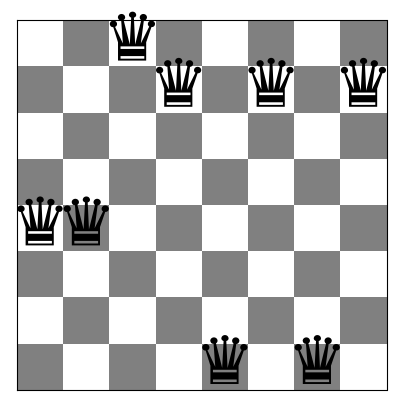

Queens (left to right) are at rows: [4 4 0 1 7 1 7 1]
Number of conflicts: 8


In [5]:
board = random_board(8)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


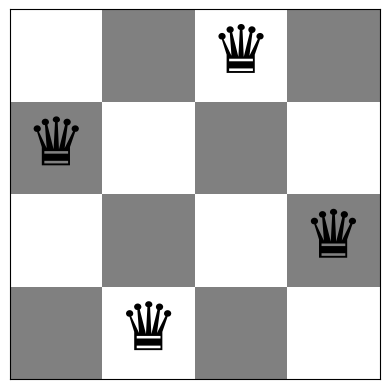

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [6]:
def steepest_ascent_hc(board):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    steps = 0
    evaluations = 1
    
    while True:
        best_h = current_h
        best_moves = []
        
        # Đánh giá TOÀN BỘ các bước đi lân cận
        for col in range(n):
            for row in range(n):
                if current_board[col] == row: continue
                
                temp_board = current_board.copy()
                temp_board[col] = row
                h = conflicts(temp_board)
                evaluations += 1
                
                if h < best_h:
                    best_h = h
                    best_moves = [temp_board]
                elif h == best_h:
                    best_moves.append(temp_board)
                    
        # Nếu không còn bước nào cải thiện hàm h -> Đạt cực trị cục bộ (Local optimum)
        if best_h >= current_h:
            break
            
        current_board = random.choice(best_moves)
        current_h = best_h
        steps += 1
        
    return current_board, current_h, steps, evaluations

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [7]:
def inefficient_stochastic_hc(board):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    steps, evaluations = 0, 1
    
    while True:
        better_moves = []
        # Vẫn duyệt toàn bộ nhưng lọc ra các bước cải thiện
        for col in range(n):
            for row in range(n):
                if current_board[col] == row: continue
                temp_board = current_board.copy()
                temp_board[col] = row
                h = conflicts(temp_board)
                evaluations += 1
                if h < current_h:
                    better_moves.append(temp_board)
                    
        if not better_moves: break
            
        # Chọn ngẫu nhiên 1 trong tất cả các bước cải thiện
        current_board = random.choice(better_moves)
        current_h = conflicts(current_board)
        evaluations += 1
        steps += 1
        
    return current_board, current_h, steps, evaluations

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [8]:
def efficient_stochastic_hc(board, max_tries=100):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    steps, evaluations, tries = 0, 1, 0
    
    # Chỉ sinh lần lượt 1 láng giềng ngẫu nhiên, nếu tốt thì chuyển luôn
    while tries < max_tries:
        if current_h == 0: break
            
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        if current_board[col] == row: continue
            
        temp_board = current_board.copy()
        temp_board[col] = row
        h = conflicts(temp_board)
        evaluations += 1
        
        if h < current_h:
            current_board = temp_board
            current_h = h
            steps += 1
            tries = 0  # Trả số lần thử về 0 sau khi cải thiện
        else:
            tries += 1 # Điều kiện dừng để tránh vòng lặp vô hạn
            
    return current_board, current_h, steps, evaluations

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [9]:
def random_restart_hc(n, max_restarts=100):
    total_steps, total_evals = 0, 0
    
    for i in range(max_restarts):
        board = np.random.randint(0, n, size=n)
        final_board, h, steps, evals = steepest_ascent_hc(board)
        total_steps += steps
        total_evals += evals
        
        # Chỉ cần có một nghiệm h=0 (thành công) thì trả về ngay
        if h == 0:
            return final_board, h, total_steps, total_evals, i + 1
            
    return final_board, h, total_steps, total_evals, max_restarts

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [23]:
def simulated_annealing(board, initial_temp=100.0, cooling_rate=0.95, min_temp=0.01):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    temp = initial_temp
    steps, evaluations = 0, 1
    
    while temp > min_temp:
        if current_h == 0: break
            
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        if current_board[col] == row: continue
            
        temp_board = current_board.copy()
        temp_board[col] = row
        h = conflicts(temp_board)
        evaluations += 1
        
        delta_e = current_h - h # Hướng tốt lên delta_e > 0
        
        if delta_e > 0:
            current_board = temp_board
            current_h = h
        else:
            # Nhận trạng thái "tệ hơn" với xác suất p
            probability = math.exp(delta_e / temp)
            if random.random() < probability:
                current_board = temp_board
                current_h = h
                
        temp *= cooling_rate
        steps += 1
        
    return current_board, current_h, steps, evaluations

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |     0.0003    |         0.66                      |41.0%|
| Ineff. Stochastic HC |     4      |    0.0003       |        0.83                        |30.0%|
| Efficient Stochastic HC |     4      |    0.0010      |     0.84                         |31.0%|
| Simulated Annealing  |     4      |     0.0010     |        0.08                        |92.0%|
| Steepest asc. HC     |     8      |    0.0035    |          1.25                     |13.0%|
| Ineff. Stochastic HC |     8      |    0.0052      |       1.34                       |12.0%|
| Efficient Stochastic HC |     8      |  0.0025      |       1.37                         |17.0%|
| Simulated Annealing  |     8      |   0.0032     |         1.43                    |9.0%|

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [17]:
import numpy as np
import time
import math
import random

def random_board(n):
    return np.random.randint(0, n, size=n)

def comb2(n): 
    return n*(n-1)//2

def conflicts(board):
    n = len(board)
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

def steepest_ascent_hc(board):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    while True:
        best_h = current_h
        best_moves = []
        for col in range(n):
            for row in range(n):
                if current_board[col] == row: continue
                temp_board = current_board.copy()
                temp_board[col] = row
                h = conflicts(temp_board)
                if h < best_h:
                    best_h = h
                    best_moves = [temp_board]
                elif h == best_h:
                    best_moves.append(temp_board)
        if best_h >= current_h: break
        current_board = random.choice(best_moves)
        current_h = best_h
    return current_board, current_h, 0, 0

def inefficient_stochastic_hc(board):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    while True:
        better_moves = []
        for col in range(n):
            for row in range(n):
                if current_board[col] == row: continue
                temp_board = current_board.copy()
                temp_board[col] = row
                h = conflicts(temp_board)
                if h < current_h: better_moves.append(temp_board)
        if not better_moves: break
        current_board = random.choice(better_moves)
        current_h = conflicts(current_board)
    return current_board, current_h, 0, 0

def efficient_stochastic_hc(board, max_tries=100):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    tries = 0
    while tries < max_tries:
        if current_h == 0: break
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        if current_board[col] == row: continue
        temp_board = current_board.copy()
        temp_board[col] = row
        h = conflicts(temp_board)
        if h < current_h:
            current_board = temp_board
            current_h = h
            tries = 0
        else:
            tries += 1
    return current_board, current_h, 0, 0

def simulated_annealing(board, initial_temp=100.0, cooling_rate=0.95, min_temp=0.01):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    temp = initial_temp
    while temp > min_temp:
        if current_h == 0: break
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        if current_board[col] == row: continue
        temp_board = current_board.copy()
        temp_board[col] = row
        h = conflicts(temp_board)
        delta_e = current_h - h
        if delta_e > 0:
            current_board = temp_board
            current_h = h
        else:
            if random.random() < math.exp(delta_e / temp):
                current_board = temp_board
                current_h = h
        temp *= cooling_rate
    return current_board, current_h, 0, 0

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [18]:
def get_conflicted_cols(board):
    n = len(board)
    conflicted = set()
    for i in range(n):
        for j in range(i+1, n):
            if board[i] == board[j] or abs(board[i]-board[j]) == j - i:
                conflicted.add(i)
                conflicted.add(j)
    return list(conflicted)

def move_single_step(board):
    n = len(board)
    col = random.randint(0, n-1)
    new_board = board.copy()
    if random.random() < 0.5 and new_board[col] < n-1: new_board[col] += 1
    elif new_board[col] > 0: new_board[col] -= 1
    return new_board

def move_col_swap(board):
    n = len(board)
    c1, c2 = random.sample(range(n), 2)
    new_board = board.copy()
    new_board[c1], new_board[c2] = new_board[c2], new_board[c1]
    return new_board

def move_dual_queen(board):
    n = len(board)
    c1, c2 = random.sample(range(n), 2)
    new_board = board.copy()
    new_board[c1], new_board[c2] = random.randint(0, n-1), random.randint(0, n-1)
    return new_board

def move_adaptive(board):
    n = len(board)
    conflicted = get_conflicted_cols(board)
    col = random.choice(conflicted) if conflicted else random.randint(0, n-1)
    new_board = board.copy()
    new_board[col] = random.randint(0, n-1)
    return new_board

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Slope của Efficient Stochastic HC: 1.92
Slope của Simulated Annealing: 1.06


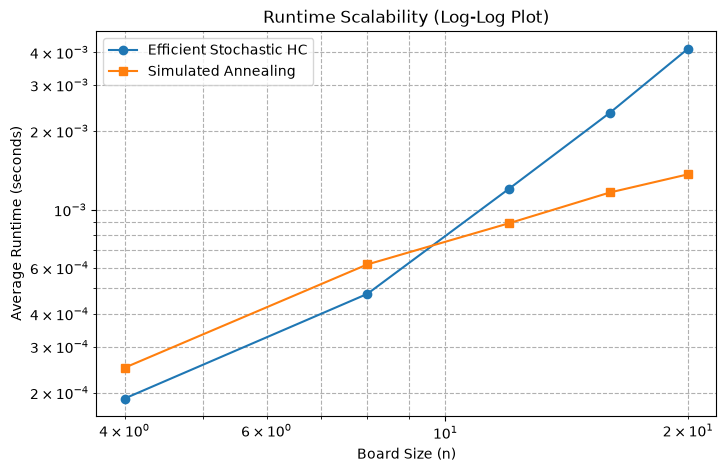

In [22]:
import numpy as np
import time
import math
import random
import matplotlib.pyplot as plt

def random_board(n):
    return np.random.randint(0, n, size=n)

def comb2(n): 
    return n*(n-1)//2

def conflicts(board):
    n = len(board)
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

def efficient_stochastic_hc(board, max_tries=100):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    tries = 0
    while tries < max_tries:
        if current_h == 0: break
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        if current_board[col] == row: continue
        temp_board = current_board.copy()
        temp_board[col] = row
        h = conflicts(temp_board)
        if h < current_h:
            current_board = temp_board
            current_h = h
            tries = 0
        else:
            tries += 1
    return current_board

def simulated_annealing(board, initial_temp=100.0, cooling_rate=0.90, min_temp=0.01):
    n = len(board)
    current_board = board.copy()
    current_h = conflicts(current_board)
    temp = initial_temp
    while temp > min_temp:
        if current_h == 0: break
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        if current_board[col] == row: continue
        temp_board = current_board.copy()
        temp_board[col] = row
        h = conflicts(temp_board)
        delta_e = current_h - h
        if delta_e > 0:
            current_board = temp_board
            current_h = h
        else:
            if random.random() < math.exp(delta_e / temp):
                current_board = temp_board
                current_h = h
        temp *= cooling_rate
    return current_board

sizes = [4, 8, 12, 16, 20]
times_esa = []
times_sa = []

# Đánh giá thời gian chạy 
for n in sizes:
    t_esa, t_sa = [], []
    for _ in range(30):
        b = random_board(n)
        
        st = time.perf_counter()
        efficient_stochastic_hc(b, max_tries=n*5)
        t_esa.append(time.perf_counter() - st)
        
        st = time.perf_counter()
        simulated_annealing(b, initial_temp=100.0, cooling_rate=0.90, min_temp=0.01)
        t_sa.append(time.perf_counter() - st)
        
    times_esa.append(np.mean(t_esa))
    times_sa.append(np.mean(t_sa))

# Tính toán Time Complexity (Slope trên đồ thị log-log)
log_sizes = np.log(sizes)
slope_esa, _ = np.polyfit(log_sizes, np.log(times_esa), 1)
slope_sa, _ = np.polyfit(log_sizes, np.log(times_sa), 1)

print(f"Slope của Efficient Stochastic HC: {slope_esa:.2f}")
print(f"Slope của Simulated Annealing: {slope_sa:.2f}")

# Vẽ đồ thị log-log
plt.figure(figsize=(8, 5))
plt.loglog(sizes, times_esa, marker='o', label='Efficient Stochastic HC')
plt.loglog(sizes, times_sa, marker='s', label='Simulated Annealing')
plt.title('Runtime Scalability (Log-Log Plot)')
plt.xlabel('Board Size (n)')
plt.ylabel('Average Runtime (seconds)')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

Single-step move & Column swap rất dễ bị mắc kẹt vào cực trị cục bộ (chất lượng nghiệm hội tụ trung bình rất kém ở khoảng 4 - 6 lỗi). Việc chỉ di chuyển 1 ô lên/xuống làm triệt tiêu khả năng thoát hiểm khỏi cấu hình lỗi, trong khi hoán đổi cột lại khiến việc điều chỉnh vị trí một quân hậu đơn lẻ trở nên không thể.

Dual-Queen move mang lại chất lượng rất tốt (xung đột thấp) do làm biến đổi hoàn toàn không gian láng giềng, mở khóa nhiều trạng thái linh hoạt hơn để chạy khỏi plateau.

Adaptive move (Tốt nhất) ưu tiên xử lý trực tiếp các quân hậu đang bị xung đột để triệt tiêu hàm chi phí ngay lập tức. Phương pháp này mang tính hướng đích cao, giúp giải quyết bài toán nhanh và thành công nhất vì nó loại bỏ việc lãng phí thời gian lấy mẫu ngẫu nhiên trên các cột đã an toàn.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [21]:
def genetic_algorithm(n, pop_size=100, max_generations=1000):
    # Khởi tạo quần thể ban đầu
    population = [random_board(n) for _ in range(pop_size)]
    
    def fitness(board):
        # Max conflicts = n*(n-1)/2, fitness cao hơn là tốt hơn
        return comb2(n) - conflicts(board)
        
    for generation in range(max_generations):
        # Đánh giá fitness và kiểm tra nghiệm
        population = sorted(population, key=lambda b: fitness(b), reverse=True)
        if conflicts(population[0]) == 0:
            return population[0], generation
            
        new_population = population[:10] # Elitism: Giữ lại 10 cá thể tốt nhất
        
        # Lai ghép (Crossover) và Đột biến (Mutation)
        weights = [fitness(b) for b in population]
        while len(new_population) < pop_size:
            parent1, parent2 = random.choices(population, weights=weights, k=2)
            crossover_point = random.randint(1, n-2)
            child = np.concatenate((parent1[:crossover_point], parent2[crossover_point:]))
            
            # Đột biến với xác suất 10%
            if random.random() < 0.1:
                child[random.randint(0, n-1)] = random.randint(0, n-1)
            new_population.append(child)
            
        population = new_population
        
    return population[0], max_generations